# Domain shift analysis: real vs. synthetic (multi-dataset)

This notebook compares real and synthetic image distributions in the **L2-normalized CLIP ViT-B/32 embedding space** (`openai/clip-vit-base-patch32`). It produces the two plots used in the paper:

- **Domain View:** joint t-SNE projection, with a *visual approximation* of the real/synthetic classifier's boundary. The logistic-regression model itself is trained and evaluated in the **original CLIP embedding space**, never in 2D.
- **Cluster View:** k-means fitted **only on real CLIP embeddings**, with each synthetic embedding assigned to its nearest real centroid. The number of clusters is selected separately for each dataset via the elbow method.

A fixed-seed random sample is selected from each domain and balanced **after skipping invalid images**. The logistic regression is evaluated with an independent, stratified **80/20 train/test split**; the reported accuracy is **test accuracy**, not training accuracy. The unsupervised descriptive plots (t-SNE and k-means) use all selected images, including the classifier's test images, but their coordinates/cluster labels are **not inputs to the classifier**.

> **Caution about the boundary in t-SNE:** t-SNE does not preserve a linear hyperplane. The dashed line is the zero contour of an interpolation of the **CLIP classifier's decision scores at the observed points**. It is for visualization only: it is not an exact projection of the separating hyperplane, nor does it measure classification accuracy.

**Requirements:** `numpy`, `scipy`, `pillow`, `matplotlib`, `scikit-learn`, `torch`, `transformers`. Configure the local dataset paths below. No training data, results, or saved figures from previous notebook runs are required.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
from scipy.interpolate import griddata
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from transformers import CLIPModel, CLIPProcessor

# ============================================================
# 1. CONFIGURATION (paths retained from the original notebook)
# ============================================================
'''DATASETS = {
    "Vessels & Boats": ("datasets_sdb/fernando_ultralytics/images/train", "datasets/sFERNANDO_FLUX29B/images"),
    "KITTI": ("datasets/kitti/images/train", "datasets_sda/sKITTI_FLUXFP8/images"),
    "African Wildlife": ("datasets/african-wildlife/images/train", "datasets/sAFRICANWILDLIFE_FLUXFP8/images"),
    "PASCAL VOC 2012": ("datasets/VOC/images/train", "datasets/sVOC_FLUXFP8/images"),
    "Home Objects": (
        "/home/josericardopenase/Escritorio/datasets/homeobjects-3K/images/train",
        "/home/josericardopenase/Escritorio/datasets/sHOMEOBJECTS_FLUXFP8/images",
    ),
    "MSCOCO subset 5k": (
        "/home/josericardopenase/Escritorio/datasets/coco_subset_5k/images/train",
        "/home/josericardopenase/Escritorio/datasets/sCOCO_FLUX/images/train",
    ),
}'''

DATASETS = {
    "Vessels & Boats": ("/home/josericardopenase/Escritorio/datasets_sdb/fernando_ultralytics/images/train", "/home/josericardopenase/Escritorio/datasets/sFERNANDO_FLUX29B/images"),
    "KITTI": ("/home/josericardopenase/Escritorio/datasets_sdb/kitti/images/train", "/home/josericardopenase/Escritorio/datasets_sda/sKITTI_FLUXFP8/images"),
    "African Wildlife": ("/home/josericardopenase/Escritorio/datasets/african-wildlife/images/train", "/home/josericardopenase/Escritorio/datasets/sAFRICANWILDLIFE_FLUXFP8/images"),
    "PASCAL VOC 2012": ("/home/josericardopenase/Escritorio/datasets_sdb/VOC/images/train2012", "/home/josericardopenase/Escritorio/datasets_sdb/sVOC_FLUXFP8/images"),
    "Home Objects": (
        "/home/josericardopenase/Escritorio/datasets/homeobjects-3K/images/train",
        "/home/josericardopenase/Escritorio/datasets/sHOMEOBJECTS_FLUXFP8/images",
    ),
    "MSCOCO subset 5k": (
        "/home/josericardopenase/Escritorio/datasets/coco_subset_5k/images/train",
        "/home/josericardopenase/Escritorio/datasets/sCOCO_FLUX/images",
    ),
}

CLIP_MODEL_ID = "openai/clip-vit-base-patch32"
# Optional local checkpoint for offline execution (must contain model + processor files).
CLIP_LOCAL_DIR = None  # e.g. "./models/clip-vit-base-patch32"
MAX_IMAGENES = 300           # Maximum VALID images per domain and dataset
RANDOM_STATE = 42
TEST_SIZE = 0.20
BATCH_SIZE = 16
K_MAX = 12                # Candidate k values: 1 ... min(K_MAX, n_real - 1)
TSNE_PERPLEXITY = 30
FIGURES_DIR = Path("figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 1. CLIP image embeddings and reproducible sampling

For each dataset we shuffle sorted file paths using the fixed random seed, skip unreadable files and extract at most `MAX_IMAGENES` valid embeddings per domain. We then truncate both sets to the same size, `n = min(n_real, n_synthetic)`. All subsequent operations use those balanced **512-dimensional, L2-normalized** image embeddings.

In [2]:
FORMATOS = {".png", ".jpg", ".jpeg", ".webp"}


def listar_imagenes(carpeta_ruta):
    carpeta = Path(carpeta_ruta)
    if not carpeta.is_dir():
        print(f"   ⚠️ Directory not found: {carpeta_ruta}")
        return []
    return sorted(p for p in carpeta.iterdir() if p.is_file() and p.suffix.lower() in FORMATOS)


def cargar_clip():
    model_id = CLIP_LOCAL_DIR or CLIP_MODEL_ID
    device = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"Loading CLIP {model_id} on {device}")
    processor = CLIPProcessor.from_pretrained(model_id)
    model = CLIPModel.from_pretrained(model_id).to(device).eval()
    return model, processor, device


def obtener_embeddings(rutas, max_fotos, model, processor, device):
    """Extract embeddings in path order, skipping invalid images; keep at most max_fotos.

    The input paths should already have been shuffled using a seeded RNG.
    """
    embeddings = []
    invalidas = 0
    lote = []

    def inferir_lote(imagenes):
        inputs = processor(images=imagenes, return_tensors="pt", padding=True).to(device)
        with torch.no_grad():
            feat = model.get_image_features(**inputs)
            # Transformers versions differ in the feature return type.
            if not isinstance(feat, torch.Tensor):
                if getattr(feat, "image_embeds", None) is not None:
                    feat = feat.image_embeds
                elif getattr(feat, "pooler_output", None) is not None:
                    feat = feat.pooler_output
                else:
                    raise TypeError(f"Unexpected CLIP image-feature return type: {type(feat)}")
            feat = F.normalize(feat.float(), p=2, dim=-1)
        return feat.cpu().numpy()

    for ruta in rutas:
        if len(embeddings) + len(lote) >= max_fotos:
            break
        try:
            with Image.open(ruta) as img:
                lote.append(img.convert("RGB"))
        except (OSError, ValueError) as exc:
            invalidas += 1
            print(f"   ⚠️ Skipping unreadable image {ruta.name}: {exc}")
            continue

        if len(lote) == BATCH_SIZE:
            embeddings.extend(inferir_lote(lote))
            lote.clear()

    if lote:
        embeddings.extend(inferir_lote(lote))

    if invalidas:
        print(f"   Skipped unreadable images: {invalidas}")
    if not embeddings:
        return np.empty((0, int(model.config.projection_dim)), dtype=np.float32)
    result = np.asarray(embeddings, dtype=np.float32)
    if result.shape[1] != int(model.config.projection_dim):
        raise ValueError(f"Expected {model.config.projection_dim}-D CLIP projections, got {result.shape[1]}D")
    return result

## 2. Determine k by the elbow method (per dataset)

We compute k-means inertia on **real embeddings only** for integer `k` from 1 to `K_MAX` (limited by the number of samples). To select the elbow without another dependency, the curve is normalized and we choose the **interior point with the largest vertical distance from the straight line between its endpoints**. This is an explicit, deterministic elbow criterion; it is **not** a silhouette-score selection or a claim that a unique knee always exists.

A small maximum deviation triggers a warning: when the curve is nearly linear, the selected k is only a weak heuristic. The diagnostic figure displays every curve and its chosen k.

In [3]:
def seleccionar_k_elbow(embs_reales, k_max=K_MAX):
    n = len(embs_reales)
    if n < 4:
        raise ValueError("At least 4 valid real embeddings are required for elbow selection.")
    valores_k = np.arange(1, min(k_max, n - 1) + 1, dtype=int)
    if len(valores_k) < 3:
        raise ValueError("At least 3 candidate k values are required.")

    inercias = np.asarray([
        KMeans(n_clusters=int(k), random_state=RANDOM_STATE, n_init=10).fit(embs_reales).inertia_
        for k in valores_k
    ], dtype=float)

    amplitud = inercias[0] - inercias[-1]
    if not np.isfinite(amplitud) or amplitud <= 0:
        raise ValueError("Cannot identify an elbow: the inertia curve is degenerate.")

    x = (valores_k - valores_k[0]) / (valores_k[-1] - valores_k[0])
    y = (inercias - inercias[-1]) / amplitud  # decreasing from 1 to 0
    separacion = (1.0 - x) - y             # distance below the endpoint chord
    separacion[0] = separacion[-1] = -np.inf
    indice = int(np.argmax(separacion))
    desviacion = float(separacion[indice])
    k_elegido = int(valores_k[indice])

    return {
        "ks": valores_k,
        "inertias": inercias,
        "k": k_elegido,
        "elbow_strength": desviacion,
        "weak_elbow": desviacion < 0.03,
    }


def ajustar_kmeans_reales(embs_reales, embs_sinteticos, elbow):
    kmeans = KMeans(n_clusters=elbow["k"], random_state=RANDOM_STATE, n_init=10)
    clusters_reales = kmeans.fit_predict(embs_reales)
    clusters_sinteticos = kmeans.predict(embs_sinteticos)
    return clusters_reales, clusters_sinteticos

## 3. Train/test classification and t-SNE

Logistic regression is trained **in the CLIP space**, with `Real = 0`, `Synthetic = 1`. The test split is random, stratified and fixed by seed. The primary reported statistic is accuracy on **held-out test embeddings**. The CLIP backbone is frozen; the classifier never receives t-SNE coordinates or cluster assignments.

The t-SNE fit is joint (real + synthetic). The values later used for drawing the approximated 2D boundary are the logistic regression's **decision scores on the original CLIP embeddings**.

In [4]:
def evaluar_separabilidad(embs_reales, embs_sinteticos):
    todos_embs = np.vstack([embs_reales, embs_sinteticos])
    y = np.concatenate([
        np.zeros(len(embs_reales), dtype=int),
        np.ones(len(embs_sinteticos), dtype=int),
    ])
    indices = np.arange(len(y))
    train_idx, test_idx = train_test_split(
        indices, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
    )
    clf = LogisticRegression(random_state=RANDOM_STATE, max_iter=2000)
    clf.fit(todos_embs[train_idx], y[train_idx])
    predicciones_test = clf.predict(todos_embs[test_idx])
    accuracy_test = accuracy_score(y[test_idx], predicciones_test)
    puntuaciones = clf.decision_function(todos_embs)

    return {
        "accuracy_test": float(accuracy_test),
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "decision_scores": puntuaciones,
    }


def proyectar_tsne(embs_reales, embs_sinteticos):
    todos_embs = np.vstack([embs_reales, embs_sinteticos])
    perplexity = min(TSNE_PERPLEXITY, len(todos_embs) - 1)
    return TSNE(
        n_components=2,
        perplexity=perplexity,
        random_state=RANDOM_STATE,
    ).fit_transform(todos_embs)

In [5]:
# ============================================================
# 4. END-TO-END PROCESSING
# ============================================================
resultados_globales = {}
rng = np.random.default_rng(RANDOM_STATE)

model, processor, device = cargar_clip()

for nombre, (ruta_real, ruta_sintetica) in DATASETS.items():
    print(f"\nProcessing dataset: {nombre}")
    rutas_reales = listar_imagenes(ruta_real)
    rutas_sinteticas = listar_imagenes(ruta_sintetica)
    if not rutas_reales or not rutas_sinteticas:
        print("   ⏭️ Skipped: no available images in one or both domains.")
        continue

    # The seed, sorted paths and fixed iteration order make the sample reproducible.
    rutas_reales = [rutas_reales[i] for i in rng.permutation(len(rutas_reales))]
    rutas_sinteticas = [rutas_sinteticas[i] for i in rng.permutation(len(rutas_sinteticas))]
    embs_reales = obtener_embeddings(rutas_reales, MAX_IMAGENES, model, processor, device)
    embs_sinteticos = obtener_embeddings(rutas_sinteticas, MAX_IMAGENES, model, processor, device)

    n = min(len(embs_reales), len(embs_sinteticos))
    if n < 10:
        print(f"   ⏭️ Skipped: only {n} valid images per domain after balancing (minimum: 10).")
        continue
    embs_reales = embs_reales[:n]
    embs_sinteticos = embs_sinteticos[:n]

    elbow = seleccionar_k_elbow(embs_reales)
    if elbow["weak_elbow"]:
        print(f"   ⚠️ Weak elbow for k={elbow['k']}; inspect the inertia curve.")
    c_reales, c_sinteticos = ajustar_kmeans_reales(embs_reales, embs_sinteticos, elbow)
    clasificacion = evaluar_separabilidad(embs_reales, embs_sinteticos)
    coordenadas_2d = proyectar_tsne(embs_reales, embs_sinteticos)

    resultados_globales[nombre] = {
        "coordenadas": coordenadas_2d,
        "n_reales": n,
        "c_reales": c_reales,
        "c_sinteticos": c_sinteticos,
        "k": elbow["k"],
        "elbow": elbow,
        **clasificacion,
    }
    print(f"   ✅ n={n} per domain | k={elbow['k']} | "
          f"test accuracy={clasificacion['accuracy_test']:.1%} "
          f"(train={clasificacion['n_train']}, test={clasificacion['n_test']})")

if not resultados_globales:
    raise RuntimeError("No datasets could be processed. Check DATASETS paths and valid image counts.")

print("\nCompleted datasets:", list(resultados_globales))

Loading CLIP openai/clip-vit-base-patch32 on cuda


2026-10-31 18:03:36.470123: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/srv/difu-paper/.venv/lib/python3.12/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(



Processing dataset: Vessels & Boats
   ✅ n=300 per domain | k=5 | test accuracy=93.3% (train=480, test=120)

Processing dataset: KITTI
   ✅ n=300 per domain | k=5 | test accuracy=100.0% (train=480, test=120)

Processing dataset: African Wildlife
   ✅ n=300 per domain | k=4 | test accuracy=99.2% (train=480, test=120)

Processing dataset: PASCAL VOC 2012
   ✅ n=300 per domain | k=4 | test accuracy=99.2% (train=480, test=120)

Processing dataset: Home Objects
   ✅ n=300 per domain | k=5 | test accuracy=97.5% (train=480, test=120)

Processing dataset: MSCOCO subset 5k
   ✅ n=300 per domain | k=5 | test accuracy=96.7% (train=480, test=120)

Completed datasets: ['Vessels & Boats', 'KITTI', 'African Wildlife', 'PASCAL VOC 2012', 'Home Objects', 'MSCOCO subset 5k']


## 4. Inspect elbow selection

This is a **diagnostic plot**, not an extra domain-gap metric. Compare elbow strengths and visually review any warnings before relying on a selected k.

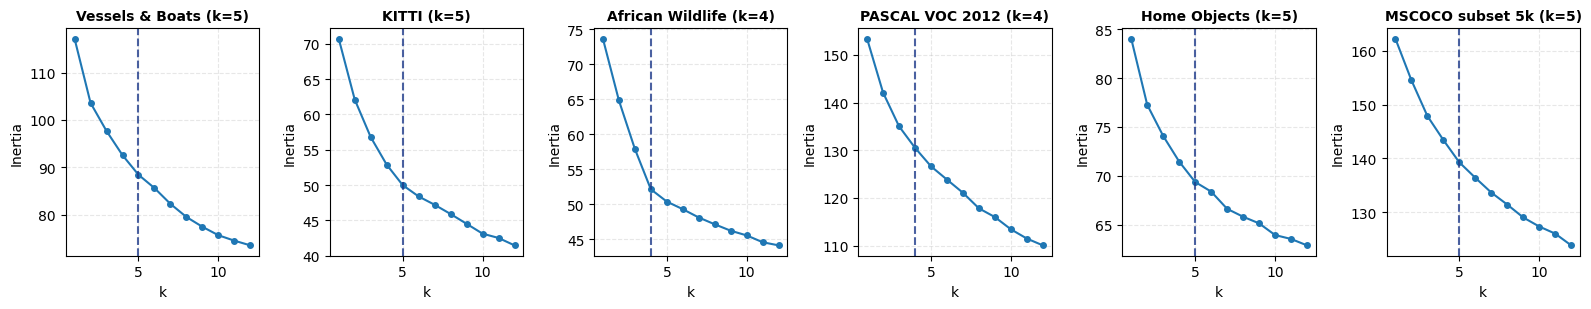

In [6]:
fig_k, axes_k = plt.subplots(1, len(resultados_globales), figsize=(16, 3.2), squeeze=False)
for ax, (nombre, datos) in zip(axes_k.flat, resultados_globales.items()):
    elbow = datos["elbow"]
    ax.plot(elbow["ks"], elbow["inertias"], "o-", linewidth=1.5, markersize=4)
    ax.axvline(elbow["k"], color="#1E3A8A", linestyle="--", alpha=0.8)
    ax.set_title(f"{nombre} (k={elbow['k']})", weight="bold", fontsize=10)
    ax.set_xlabel("k")
    ax.set_ylabel("Inertia")
    ax.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "elbow_method.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

## 5. Domain View — real vs. synthetic

The background tint and dashed contour are interpolated from the **512-D CLIP classifier scores evaluated at the observed images**. We use linear interpolation in t-SNE coordinates; the zero contour gives a **2D approximation**. It should **not** be interpreted as the exact image of the 512-D hyperplane. It may be disconnected or missing where the 2D projection does not adequately represent classification structure.

The percentage in each panel is **held-out test accuracy** computed in CLIP space. We preserve the original blue/orange markers, figure layout and output filename.

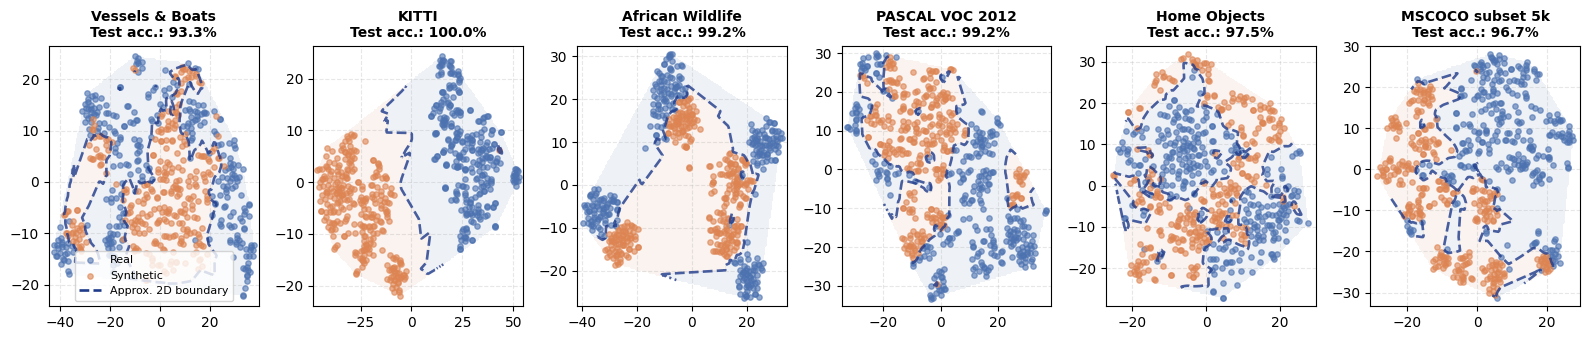

In [9]:
def dibujar_frontera_aproximada(ax, coordenadas, scores, resolution=160):
    """Visual approximation in t-SNE: interpolate CLIP decision scores, NOT a 2D classifier.

    Linear interpolation is defined only inside the convex hull of observed points.
    Areas outside this hull are left unshaded; the 0-contour is not an exact
    transformation of the classifier hyperplane.
    """
    margen = 2.0
    x = np.linspace(coordenadas[:, 0].min() - margen,
                    coordenadas[:, 0].max() + margen, resolution)
    y = np.linspace(coordenadas[:, 1].min() - margen,
                    coordenadas[:, 1].max() + margen, resolution)
    xx, yy = np.meshgrid(x, y)
    zz = griddata(coordenadas, scores, (xx, yy), method="linear")
    validos = zz[np.isfinite(zz)]
    if not len(validos) or not (validos.min() < 0 < validos.max()):
        return False

    ax.contourf(xx, yy, zz, levels=[-np.inf, 0, np.inf],
                colors=["#4C72B0", "#DD8452"], alpha=0.09, zorder=0)
    ax.contour(xx, yy, zz, levels=[0], colors=["#1E3A8A"],
               linestyles="--", linewidths=1.9, alpha=0.8, zorder=3)
    return True


fig1, axes1 = plt.subplots(1, len(resultados_globales), figsize=(16, 3.5), squeeze=False)
for idx, (nombre, datos) in enumerate(resultados_globales.items()):
    ax = axes1.flat[idx]
    coor = datos["coordenadas"]
    n_real = datos["n_reales"]

    dibujar_frontera_aproximada(ax, coor, datos["decision_scores"])
    ax.scatter(coor[:n_real, 0], coor[:n_real, 1], c="#4C72B0",
               label="Real", alpha=0.6, s=15, zorder=2)
    ax.scatter(coor[n_real:, 0], coor[n_real:, 1], c="#DD8452",
               label="Synthetic", alpha=0.6, s=15, zorder=2)
    ax.set_title(f"{nombre}\nTest acc.: {datos['accuracy_test']:.1%}",
                 weight="bold", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.3, zorder=1)
    if idx == 0:
        from matplotlib.lines import Line2D
        proxy = Line2D([0], [0], linestyle="--", color="#1E3A8A",
                       linewidth=1.9, label="Approx. 2D boundary")
        handles, labels = ax.get_legend_handles_labels()
        ax.legend(handles + [proxy], labels + ["Approx. 2D boundary"], fontsize=8)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "tsne_real_vs_synthetic.png", dpi=500,
            bbox_inches="tight", facecolor="white")
plt.show()

## 6. Cluster View — real-data semantic partitions

Colors denote **real-trained k-means clusters**, not dataset classes. Real samples use **circles** and synthetic samples use **squares**, both assigned in the **original normalized CLIP space**. t-SNE is used exclusively for display. Colors are consistent within each dataset for its selected `k`.

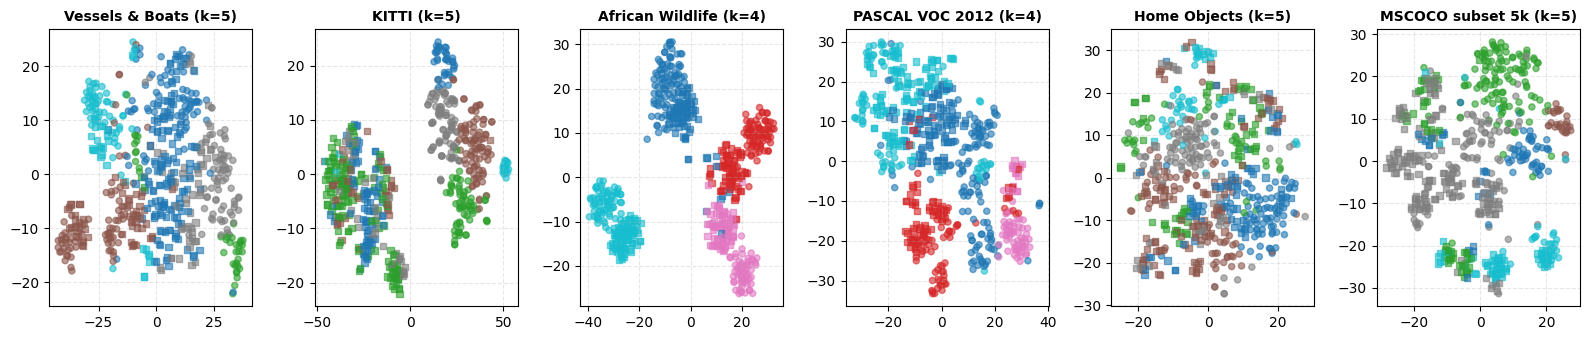

In [8]:
fig2, axes2 = plt.subplots(1, len(resultados_globales), figsize=(16, 3.5), squeeze=False)
for idx, (nombre, datos) in enumerate(resultados_globales.items()):
    ax = axes2.flat[idx]
    coor = datos["coordenadas"]
    n_real = datos["n_reales"]
    k = datos["k"]
    cmap = "tab10" if k <= 10 else "tab20"

    ax.scatter(coor[:n_real, 0], coor[:n_real, 1],
               c=datos["c_reales"], cmap=cmap, vmin=0, vmax=k-1,
               marker="o", s=20, alpha=0.6)
    ax.scatter(coor[n_real:, 0], coor[n_real:, 1],
               c=datos["c_sinteticos"], cmap=cmap, vmin=0, vmax=k-1,
               marker="s", s=20, alpha=0.6)

    ax.set_title(f"{nombre} (k={k})", weight="bold", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "tsne_semantic_clusters.png", dpi=500,
            bbox_inches="tight", facecolor="white")
plt.show()

## Reproducibility checklist

- Model: `openai/clip-vit-base-patch32` (CLIP ViT-B/32, 512-D image projections); L2 normalization before analysis.
- Per dataset: fixed-seed random sampling of up to 300 valid real and 300 valid synthetic images, followed by exact balancing. The console prints the achieved `n`.
- k-means: trained only on real CLIP embeddings; `k` is selected via an explicit elbow rule and the inertia curves are saved.
- Synthetic images: assigned to their nearest **real** centroid, in the original CLIP embedding space.
- t-SNE: joint real/synthetic projection, visualization only.
- Logistic regression: train/test = 80/20 (stratified), input = CLIP embeddings; accuracy computed on held-out test data.
- Domain View dashed contour: interpolation of CLIP decision scores in 2D, **not** a projected hyperplane or a substitute for the test accuracy.
- Outputs: `figures/elbow_method.png`, `figures/tsne_real_vs_synthetic.png`, `figures/tsne_semantic_clusters.png`.

The notebook intentionally **does not** include Wasserstein distance, centroid shift, KL divergence, mixed-effects regression, or tables of detection performance: those analyses are not used in the paper's domain-shift section.